<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# <center> Проект: Анализ резюме из HeadHunter
   

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла.

In [2]:
# В файле поля разделены точкой с запятой.
data_url = 'https://drive.usercontent.google.com/download?id=1Kb78mAWYKcYlellTGhIjPI-bCcKbGuTn&export=download&confirm=t'
hh_data = pd.read_csv(data_url, sep=';')

print('Версия Pandas:', pd.__version__)
print('Размерность таблицы:', hh_data.shape)

Версия Pandas: 2.2.3
Размерность таблицы: (44744, 12)


2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [3]:
print('Первые пять строк:')
display(hh_data.head())

print('\nПоследние пять строк:')
display(hh_data.tail())

print('\nПримеры значений поля «Пол, возраст»:')
print(hh_data['Пол, возраст'].head().to_string(index=False))

3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

4. Обратите внимание на информацию о числе непустых значений.

In [4]:
hh_data.info()

missing_counts = hh_data.isna().sum()

print('\nСтолбцы с пропусками:')
print(missing_counts[missing_counts > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Пол, возраст                     44744 non-null  object
 1   ЗП                               44744 non-null  object
 2   Ищет работу на должность:        44744 non-null  object
 3   Город, переезд, командировки     44744 non-null  object
 4   Занятость                        44744 non-null  object
 5   График                           44744 non-null  object
 6   Опыт работы                      44576 non-null  object
 7   Последнее/нынешнее место работы  44743 non-null  object
 8   Последняя/нынешняя должность     44742 non-null  object
 9   Образование и ВУЗ                44744 non-null  object
 10  Обновление резюме                44744 non-null  object
 11  Авто                             44744 non-null  object
dtypes: object(12)
memory usage: 4.1+

5. Выведите основную статистическую информацию о столбцах.


In [5]:
display(hh_data.describe(include='all'))

# Считаем разные описания стажа. Пропуски в это число не входят.
print('\nУникальных описаний опыта:', hh_data['Опыт работы'].nunique())
print()
print(hh_data['Ищет работу на должность:'].value_counts().head())


Уникальных описаний опыта: 44413

Ищет работу на должность:
Системный администратор    3099
Инженер                     966
Аналитик                    809
Менеджер проектов           745
Руководитель проекта        718
Name: count, dtype: int64


### Выводы

Часть данных пока нельзя анализировать как числа или даты. Например, пол, возраст и дата рождения записаны в одном поле, а зарплата хранится вместе с валютой. Эти поля нужно разобрать перед анализом.

Пропуски есть только в трёх столбцах. Больше всего их в опыте работы: 168. Этот столбец содержит 44 413 разных описаний, поэтому сравнивать стаж удобнее после перевода в месяцы.

# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [6]:
education_by_prefix = {
    'высшее образование': 'высшее',
    'среднее образование': 'среднее',
    'среднее специальное': 'среднее специальное',
    'неоконченное высшее': 'неоконченное высшее',
}


def get_education(text):
    """Определяет уровень образования по первым двум словам."""
    words = text.lower().split()
    # По первым двум словам можно различить все четыре категории.
    prefix = ' '.join(words[:2])
    return education_by_prefix[prefix]


hh_data['Образование'] = hh_data['Образование и ВУЗ'].apply(get_education)
education_counts = hh_data['Образование'].value_counts()
print(education_counts)

hh_data = hh_data.drop(columns='Образование и ВУЗ')

Образование
высшее                 33863
среднее специальное     5765
неоконченное высшее     4557
среднее                  559
Name: count, dtype: int64


2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина.
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '.
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [7]:
# Первые две части строки содержат пол и возраст.
gender_age_parts = hh_data['Пол, возраст'].str.split(',')
gender_text = gender_age_parts.str[0].str.strip()
age_text = gender_age_parts.str[1].str.strip()

hh_data['Пол'] = gender_text.str[0]
hh_data['Возраст'] = age_text.str.split().str[0].astype(int)

women_percent = (hh_data['Пол'] == 'Ж').mean() * 100
mean_age = hh_data['Возраст'].mean()
print('Доля женских резюме:', round(women_percent, 2), '%')
print('Средний возраст:', round(mean_age, 1))

hh_data = hh_data.drop(columns='Пол, возраст')

Доля женских резюме: 19.07 %
Средний возраст: 32.2


3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**.

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [8]:
def experience_months(text):
    """Переводит общий стаж в начале строки в месяцы."""
    if pd.isna(text) or text.strip() == 'Не указано':
        return np.nan

    words = text.split()
    assert words[:2] == ['Опыт', 'работы']
    total_months = 0

    # После слов «Опыт работы» идут одна или две пары: число и единица.
    # Остальной текст описывает отдельные места работы.
    for position in (2, 4):
        if position + 1 >= len(words):
            break

        number = words[position]
        unit = words[position + 1]
        if not number.isdigit():
            break

        if unit in ('год', 'года', 'лет'):
            total_months += int(number) * 12
        elif unit in ('месяц', 'месяца', 'месяцев'):
            total_months += int(number)
        else:
            break

    return total_months


experience = hh_data['Опыт работы'].apply(experience_months)
hh_data['Опыт работы (месяц)'] = experience
print('Медианный стаж, мес.:', experience.median())

hh_data = hh_data.drop(columns='Опыт работы')

Медианный стаж, мес.: 100.0


4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , …
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [9]:
million_cities = [
    'Новосибирск', 'Екатеринбург', 'Нижний Новгород', 'Казань',
    'Челябинск', 'Омск', 'Самара', 'Ростов-на-Дону', 'Уфа',
    'Красноярск', 'Пермь', 'Воронеж', 'Волгоград',
]


def city_group(city):
    """Относит город к одной из четырёх групп."""
    if city in ('Москва', 'Санкт-Петербург'):
        return city
    if city in million_cities:
        return 'город миллионник'
    return 'другие'


location = hh_data['Город, переезд, командировки']
city_names = location.str.split(',', n=1).str[0].str.strip()
hh_data['Город'] = city_names.apply(city_group)

# Проверяем отрицания отдельно, чтобы «не готов» не попало в согласие.
mentions_move = location.str.contains('переезду|хочу переехать')
refuses_move = location.str.contains('не готова? к переезду')
ready_to_move = mentions_move & ~refuses_move

# Если командировки не упомянуты, считаем, что соискатель не готов.
mentions_travel = location.str.contains('командировкам')
refuses_travel = location.str.contains('не готова? к (?:редким )?командировкам')
ready_to_travel = mentions_travel & ~refuses_travel

hh_data['Готовность к переезду'] = ready_to_move
hh_data['Готовность к командировкам'] = ready_to_travel

petersburg_percent = (hh_data['Город'] == 'Санкт-Петербург').mean() * 100
ready_for_both_percent = (ready_to_move & ready_to_travel).mean() * 100
print('Доля резюме из Санкт-Петербурга:', round(petersburg_percent), '%')
print('Готовы к переезду и командировкам:', round(ready_for_both_percent), '%')

hh_data = hh_data.drop(columns='Город, переезд, командировки')

Доля резюме из Санкт-Петербурга: 11 %
Готовы к переезду и командировкам: 32 %


5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [10]:
employments = [
    'полная занятость', 'частичная занятость', 'проектная работа',
    'волонтерство', 'стажировка',
]

schedules = [
    'полный день', 'сменный график', 'гибкий график',
    'удаленная работа', 'вахтовый метод',
]

# В одном резюме может быть несколько вариантов занятости и графика.
employment_options = hh_data['Занятость'].str.split(', ')
schedule_options = hh_data['График'].str.split(', ')

# Чередуем столбцы занятости и графика, как в таблице для сверки.
for employment, schedule in zip(employments, schedules):
    hh_data[employment] = employment_options.apply(lambda options: employment in options)
    hh_data[schedule] = schedule_options.apply(lambda options: schedule in options)

project_and_volunteering = hh_data['проектная работа'] & hh_data['волонтерство']
shift_and_flexible = hh_data['вахтовый метод'] & hh_data['гибкий график']
print('Проектная работа и волонтерство:', project_and_volunteering.sum())
print('Вахта и гибкий график:', shift_and_flexible.sum())

hh_data = hh_data.drop(columns=['Занятость', 'График'])

Проектная работа и волонтерство: 436
Вахта и гибкий график: 2311


6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**.
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата,
* "proportion" - пропорция,
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования:
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [11]:
rates_url = 'https://lms-cdn.skillfactory.ru/assets/courseware/v1/15abf80f45a2f3e93c3274101b451c67/asset-v1:skillfactory+MIFIML-1sem+2026+type@asset+block/ExchangeRates.zip'
rates = pd.read_csv(
    rates_url,
    compression='zip',
    usecols=['currency', 'date', 'close', 'proportion'],
)

rates['date'] = pd.to_datetime(rates['date'], format='%d/%m/%y').dt.date

currency_codes = {
    'руб.': 'RUB',
    'бел.руб.': 'BYN',
    'грн.': 'UAH',
    'сум': 'UZS',
}

salary_parts = hh_data['ЗП'].str.split()
hh_data['salary_amount'] = salary_parts.str[0].astype(int)
hh_data['currency'] = salary_parts.str[1].replace(currency_codes)

# В исходном файле день стоит перед месяцем. Для курса время не нужно.
resume_dates = pd.to_datetime(
    hh_data['Обновление резюме'],
    format='%d.%m.%Y %H:%M',
).dt.date
hh_data['date'] = resume_dates

# Левое объединение сохраняет и рублёвые резюме.
hh_data = hh_data.merge(
    rates,
    on=['currency', 'date'],
    how='left',
    validate='many_to_one',
)

# Для рублёвых резюме пересчёт не нужен.
ruble_salary = hh_data['currency'] == 'RUB'
hh_data.loc[ruble_salary, ['close', 'proportion']] = 1
assert hh_data[['close', 'proportion']].notna().all().all()

# Курс может быть указан за несколько единиц валюты. Делим на их число.
salary_at_rate = hh_data['salary_amount'] * hh_data['close']
hh_data['ЗП (руб)'] = salary_at_rate / hh_data['proportion']
median_salary = hh_data['ЗП (руб)'].median()
print('Медианная зарплата, руб.:', median_salary)
print('Ответ в тысячах:', round(median_salary / 1000))

hh_data['Обновление резюме'] = hh_data['date']
temporary_columns = ['ЗП', 'salary_amount', 'currency', 'date', 'close', 'proportion']
hh_data = hh_data.drop(columns=temporary_columns)
print()
hh_data.info()


Медианная зарплата, руб.: 59019.0
Ответ в тысячах: 59

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Ищет работу на должность:        44744 non-null  object 
 1   Последнее/нынешнее место работы  44743 non-null  object 
 2   Последняя/нынешняя должность     44742 non-null  object 
 3   Обновление резюме                44744 non-null  object 
 4   Авто                             44744 non-null  object 
 5   Образование                      44744 non-null  object 
 6   Пол                              44744 non-null  object 
 7   Возраст                          44744 non-null  int64  
 8   Опыт работы (месяц)              44574 non-null  float64
 9   Город                            44744 non-null  object 
 10  Готовность к переезду            44744 non-null  bool   
 11  Готовность к командировка

# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

In [12]:
def show_distribution(values, label):
    """Показывает распределение и основные числа по признаку."""
    fig = px.histogram(
        x=values.dropna(),
        histnorm='percent',
        marginal='box',
        title='Распределение: ' + label,
        labels={'x': label, 'y': 'Доля резюме, %'},
    )
    fig.show()

    # По процентилям видно, где лежат центральные 80% значений.
    summary = values.describe(percentiles=[.1, .25, .5, .75, .9])
    display(summary)
    print('Мода:', values.mode().tolist())


show_distribution(hh_data['Возраст'], 'Возраст, лет')

count    44744.000000
mean        32.196741
std          7.929800
min         14.000000
10%         24.000000
25%         27.000000
50%         31.000000
75%         36.000000
90%         43.000000
max        100.000000
Name: Возраст, dtype: float64

Мода: [30]


### Выводы

Основная часть резюме приходится на возраст от 24 до 43 лет. Чаще всего встречается возраст 30 лет. Справа хвост длиннее. Старшие возрасты встречаются реже, но уходят далеко от основной группы. В данных указан возраст от 14 до 100 лет. Обе крайние записи стоит проверить.

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

In [13]:
show_distribution(hh_data['Опыт работы (месяц)'], 'Опыт работы, месяцев')

count    44574.000000
mean       114.418944
std         79.047861
min          1.000000
10%         27.000000
25%         57.000000
50%        100.000000
75%        154.000000
90%        218.000000
max       1188.000000
Name: Опыт работы (месяц), dtype: float64

Мода: [81.0]


### Выводы

Опыт работы распределён неравномерно. Чаще всего встречается стаж 81 месяц, а около 80% значений лежат между 27 и 218 месяцами. Разброс от 1 до 1188 месяцев в основном растягивает правый хвост. Максимум означает 99 лет стажа, что выглядит ошибкой в данных и требует отдельной проверки.

3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака возраста? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


In [14]:
salary_col = 'ЗП (руб)'
salary_values = hh_data[salary_col]
show_distribution(salary_values, 'Желаемая зарплата, руб.')

# Высокие зарплаты теряются на общей гистограмме. Покажем их отдельно.
above_million = salary_values[salary_values > 1_000_000]
high_salaries = above_million.sort_values().reset_index(drop=True) / 1000
resume_numbers = range(1, len(high_salaries) + 1)

fig = px.scatter(
    x=resume_numbers,
    y=high_salaries,
    title=f'Желаемая зарплата выше 1 млн руб.: {len(high_salaries)} резюме',
    labels={'x': 'Номер резюме в выборке', 'y': 'Желаемая зарплата, тыс. руб.'},
)
fig.show()
print('\nВыше 1 млн руб.:', len(high_salaries))

count    4.474400e+04
mean     7.653354e+04
std      1.359315e+05
min      1.000000e+00
10%      2.500000e+04
25%      3.708220e+04
50%      5.901900e+04
75%      9.500000e+04
90%      1.500000e+05
max      2.430488e+07
Name: ЗП (руб), dtype: float64

Мода: [50000.0]



Выше 1 млн руб.: 5


### Выводы

Для большинства соискателей ориентир заметно ниже миллиона: около 80% указали от 25 до 150 тыс. руб., а чаще всего встречается сумма 50 тыс. руб. Общий размах от 1 руб. до 24,3 млн руб. плохо описывает обычное резюме. Зарплат выше миллиона всего пять. Минимум и такие высокие суммы стоит проверить отдельно.

4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

In [15]:
# Эту выборку используем и в следующих сравнениях.
salary_under_million = hh_data.loc[hh_data[salary_col] < 1_000_000]
education_medians = salary_under_million.groupby('Образование')[salary_col].median()
education_medians = education_medians.sort_values()

fig = px.bar(
    x=education_medians / 1000,
    y=education_medians.index,
    orientation='h',
    title='Медианная зарплата по образованию',
    labels={'x': 'Медианная зарплата, тыс. руб.', 'y': 'Образование'},
)
fig.show()
display(education_medians)

Образование
среднее специальное    40000.0
среднее                40000.0
неоконченное высшее    50000.0
высшее                 60000.0
Name: ЗП (руб), dtype: float64

### Выводы

В выборке с зарплатами ниже 1 млн руб. сильнее всего выделяется высшее образование. Медиана в этой группе на 20 тыс. руб. выше, чем у групп со средним и средним специальным образованием, где она самая низкая. Образование может помочь в прогнозе, но его вклад лучше проверять вместе с профессией и опытом.

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

In [16]:
city_salaries = salary_under_million.copy()
city_salaries['Зарплата, тыс. руб.'] = city_salaries[salary_col] / 1000

fig = px.box(
    city_salaries,
    x='Зарплата, тыс. руб.',
    y='Город',
    color='Город',
    title='Распределение зарплат ниже 1 млн руб. по городам',
    labels={'Город': 'Категория города'},
)
fig.update_layout(showlegend=False)
fig.show()

# Максимум группы может лежать за пределами усов диаграммы.
city_stats = salary_under_million.groupby('Город')[salary_col].agg(['min', 'median', 'max'])
display(city_stats)

,min,median,max
Город,,,
Москва,1.0,85000.0,900000.0
Санкт-Петербург,1.0,60000.0,645171.0
город миллионник,1.0,40000.0,511681.6
другие,1.0,40000.0,923983.0


### Выводы

Москва выделяется по типичному уровню ожиданий: её медиана более чем вдвое выше, чем у городов-миллионников и группы «другие». Санкт-Петербург находится между ними. При этом самый широкий размах и максимум, около 924 тыс. руб., у группы «другие». Один максимум плохо описывает группу. Для прогноза полезнее учитывать то, как различаются распределения зарплат по городам.

6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

In [17]:
move_col = 'Готовность к переезду'
travel_col = 'Готовность к командировкам'
# Для этого сравнения берём все резюме, включая зарплаты от 1 млн руб.
mobility_stats = hh_data.groupby([move_col, travel_col], as_index=False)[salary_col].median()

ready_for_both = mobility_stats[move_col] & mobility_stats[travel_col]
median_for_both = mobility_stats.loc[ready_for_both, salary_col].iloc[0]

# На графике подписи «Да» и «Нет» читаются проще, чем True и False.
mobility_stats['Медиана, тыс. руб.'] = mobility_stats[salary_col] / 1000
for column in [move_col, travel_col]:
    mobility_stats[column] = mobility_stats[column].map({False: 'Нет', True: 'Да'})

fig = px.bar(
    mobility_stats,
    x=move_col,
    y='Медиана, тыс. руб.',
    color=travel_col,
    barmode='group',
    title='Медианная зарплата по готовности к переезду и командировкам',
)
fig.show()
display(mobility_stats)
print('Готовы к обоим, тыс. руб.:', round(median_for_both / 1000))

,Готовность к переезду,Готовность к командировкам,ЗП (руб),"Медиана, тыс. руб."
0,Нет,Нет,40000.000,40.000000
1,Нет,Да,60000.000,60.000000
2,Да,Нет,50000.000,50.000000
3,Да,Да,65849.455,65.849455


Готовы к обоим, тыс. руб.: 66


### Выводы

В этой выборке медианы заметнее различаются по готовности к командировкам, чем по готовности к переезду. Например, среди тех, кто не готов переезжать, готовность к поездкам соответствует разнице в 20 тыс. руб. Самая высокая медиана, около 66 тыс. руб., у тех, кто готов к обоим вариантам. Часть разницы может объясняться составом групп, например профессиями и опытом.

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

In [18]:
age_education = hh_data.pivot_table(
    index='Образование',
    columns='Возраст',
    values=salary_col,
    aggfunc='median',
)

# Пустая ячейка означает, что для этой группы медианы нет.
fig = px.imshow(
    age_education / 1000,
    aspect='auto',
    color_continuous_scale='YlGnBu',
    title='Медианная зарплата по возрасту и образованию',
    labels={'x': 'Возраст, лет', 'y': 'Образование', 'color': 'Медиана, тыс. руб.'},
)
fig.show()

# Для сравнения медиан смотрим и на число резюме в каждой группе.
ages = [20, 25, 30, 35, 40]
resume_counts = hh_data.pivot_table(
    index='Образование',
    columns='Возраст',
    values=salary_col,
    aggfunc='count',
)
display(age_education[ages])
display(resume_counts[ages])

Возраст,20,25,30,35,40
Образование,,,,,
высшее,30000.0,50000.0,65000.0,70000.0,90000.0
неоконченное высшее,31000.0,40000.0,50000.0,60000.0,60000.0
среднее,29000.0,45000.0,45000.0,45000.0,40000.0
среднее специальное,30000.0,40000.0,40000.0,45000.0,45000.0


Возраст,20,25,30,35,40
Образование,,,,,
высшее,79.0,1604.0,2234.0,1415.0,753.0
неоконченное высшее,142.0,236.0,273.0,147.0,54.0
среднее,26.0,29.0,28.0,17.0,11.0
среднее специальное,158.0,343.0,299.0,155.0,59.0


### Выводы

Сильнее всего медианы в 20 и 40 лет различаются у соискателей с высшим образованием: 30 и 90 тыс. руб. У остальных групп разница меньше. На карте видны зарплатные ожидания разных людей, поэтому по ней нельзя проследить карьеру отдельного соискателя. В малочисленных группах отдельные значения сильнее влияют на медиану.

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

In [19]:
scatter_data = hh_data[['Возраст', 'Опыт работы (месяц)']].dropna().copy()
experience = scatter_data['Опыт работы (месяц)']
scatter_data['Опыт, лет'] = experience / 12

# Считаем разницу в месяцах: на графике близкие точки сливаются с линией.
age_in_months = scatter_data['Возраст'] * 12
excess_months = experience - age_in_months
above_diagonal = excess_months > 0
on_diagonal = excess_months == 0
scatter_data['Превышение, мес.'] = excess_months
scatter_data['Группа'] = np.where(above_diagonal, 'Выше диагонали', 'Остальные резюме')

fig = px.scatter(
    scatter_data,
    x='Возраст',
    y='Опыт, лет',
    color='Группа',
    opacity=.45,
    hover_data=['Опыт работы (месяц)', 'Превышение, мес.'],
    title='Опыт работы и возраст соискателей',
    labels={'Возраст': 'Возраст, лет'},
)
fig.add_scatter(x=[0, 100], y=[0, 100], mode='lines', name='Стаж равен возрасту')
fig.show()

anomalies = scatter_data.loc[above_diagonal].sort_values('Превышение, мес.')
anomalies = anomalies.reset_index(drop=True)
fig = px.scatter(
    anomalies,
    x=anomalies.index + 1,
    y='Превышение, мес.',
    log_y=True,
    hover_data=['Возраст', 'Опыт работы (месяц)'],
    title='На сколько месяцев стаж превышает возраст',
    labels={'x': 'Номер точки в таблице', 'Превышение, мес.': 'Превышение, мес. (лог. шкала)'},
)
fig.show()

print('Строго выше прямой:', above_diagonal.sum())
print('Точно на прямой:', on_diagonal.sum())
columns = ['Возраст', 'Опыт работы (месяц)', 'Превышение, мес.']
display(anomalies[columns].rename(index=lambda i: i + 1))

Строго выше прямой: 7
Точно на прямой: 0


,Возраст,Опыт работы (месяц),"Превышение, мес."
1,36,434.0,2.0
2,34,411.0,3.0
3,34,416.0,8.0
4,18,271.0,55.0
5,28,470.0,134.0
6,14,477.0,309.0
7,48,1188.0,612.0


### Выводы

Есть семь резюме, в которых стаж больше возраста. Это видно по разнице в месяцах. Две точки выглядят так, будто лежат на прямой, но стаж в них превышает возраст на 2 и 3 месяца. Такие записи стоит проверить перед анализом связи стажа с зарплатой.

**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


In [20]:
# Для обоих графиков берём одну выборку: зарплаты ниже 1 млн руб.
def show_salary_by_gender(feature, label, title):
    """Сравнивает медианы и число резюме в группах по полу."""
    salary_groups = salary_under_million.groupby([feature, 'Пол'])[salary_col]
    group_stats = salary_groups.agg(['median', 'size']).reset_index()
    group_stats = group_stats.rename(columns={'size': 'Число резюме'})
    group_stats['Медиана, тыс. руб.'] = group_stats['median'] / 1000
    group_stats[label] = group_stats[feature].map({False: 'Нет', True: 'Да'})
    group_stats['Пол'] = group_stats['Пол'].map({'Ж': 'Женщины', 'М': 'Мужчины'})

    fig = px.bar(
        group_stats,
        x=label,
        y='Медиана, тыс. руб.',
        color='Пол',
        barmode='group',
        hover_data=['Число резюме'],
        title=title,
    )
    fig.show()

    columns = [label, 'Пол', 'Медиана, тыс. руб.', 'Число резюме']
    display(group_stats[columns])


show_salary_by_gender(
    'удаленная работа',
    'Предпочтение удалённой работы',
    'Желаемая зарплата по полу и предпочтению удалённой работы',
)
show_salary_by_gender(
    'Готовность к командировкам',
    'Готовность к командировкам',
    'Желаемая зарплата по полу и готовности к командировкам',
)

,Предпочтение удалённой работы,Пол,"Медиана, тыс. руб.",Число резюме
0,Нет,Женщины,50.0,5889
1,Нет,Мужчины,60.0,23831
2,Да,Женщины,45.0,2643
3,Да,Мужчины,60.0,12375


,Готовность к командировкам,Пол,"Медиана, тыс. руб.",Число резюме
0,Нет,Женщины,35.00000,3224
1,Нет,Мужчины,45.00000,9878
2,Да,Женщины,59.31625,5308
3,Да,Мужчины,65.00000,26328


### Выводы

Разница между медианами мужчин и женщин меняется в зависимости от группы. Среди тех, кто отметил удалёнку, она больше: 15 тыс. руб. против 10 тыс. руб. У мужчин медиана одинакова, а у женщин в этой группе она ниже.

Среди готовых к командировкам картина другая: ожидания выше у обоих полов, а разница между медианами меньше. Группы могут различаться по профессиям, опыту и городам, поэтому из этих графиков нельзя однозначно сказать, чем именно объясняется разница.

# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их.

In [21]:
# Сохраняем hh_data для повторного запуска очистки.
clean_data = hh_data.drop_duplicates().copy()
duplicate_count = len(hh_data) - len(clean_data)

print('Полные дубликаты:', duplicate_count)
print('Строк после удаления:', len(clean_data))


Полные дубликаты: 161
Строк после удаления: 44583


2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах.

In [22]:
experience_col = 'Опыт работы (месяц)'
missing_counts = clean_data.isna().sum()

# Показываем только столбцы с пропусками.
display(missing_counts[missing_counts > 0])
print('Пропуски в опыте:', missing_counts[experience_col])

Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
Опыт работы (месяц)                168
dtype: int64

Пропуски в опыте: 168


3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [23]:
work_columns = [
    'Последнее/нынешнее место работы',
    'Последняя/нынешняя должность',
]
clean_data = clean_data.dropna(subset=work_columns).copy()

# Медиану считаем после удаления строк без места работы или должности.
experience_median = clean_data[experience_col].median()
clean_data[experience_col] = clean_data[experience_col].fillna(experience_median)
experience_mean = clean_data[experience_col].mean()

print('Медиана для заполнения:', experience_median)
print('Средний опыт после заполнения:', experience_mean)
print('Ответ:', round(experience_mean))

Медиана для заполнения: 100.0
Средний опыт после заполнения: 114.35777573405711
Ответ: 114


4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [24]:
# Зарплаты ровно на границах оставляем.
salary = clean_data['ЗП (руб)']
salary_outliers = (salary < 1_000) | (salary > 1_000_000)
print('Выбросы по зарплате:', salary_outliers.sum())

clean_data = clean_data.loc[~salary_outliers].copy()

Выбросы по зарплате: 89


5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [25]:
# Стаж и возраст сравниваем в месяцах. Равные значения оставляем.
age_in_months = clean_data['Возраст'] * 12
experience_outliers = clean_data[experience_col] > age_in_months
print('Опыт превышает возраст:', experience_outliers.sum())

clean_data = clean_data.loc[~experience_outliers].copy()

Опыт превышает возраст: 7


6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

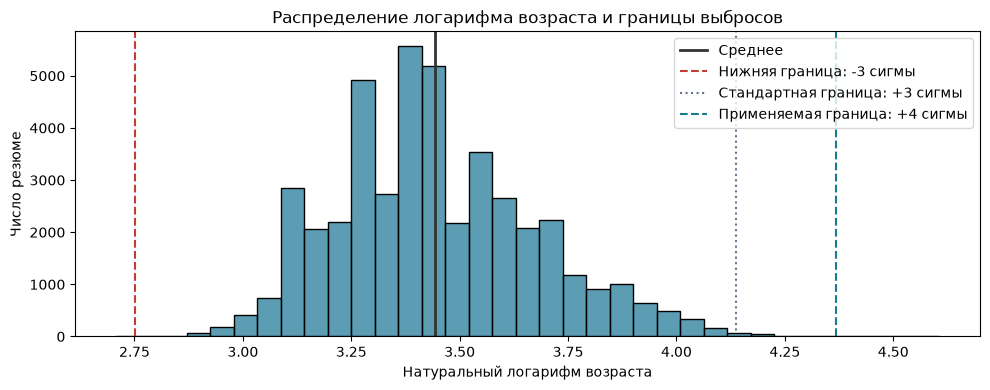

Выбросы по возрасту: 3


,Возраст,Опыт работы (месяц),ЗП (руб),z-отклонение
31137,15,2.0,10000.0,-3.186269
32950,15,3.0,2000.0,-3.186269
33654,100,30.0,60000.0,5.027199



Размер после очистки: (44482, 23)
Осталось пропусков: 0


In [26]:
# Логарифм сжимает правый хвост распределения.
log_age = np.log(clean_data['Возраст'])
mean_log = log_age.mean()
std_log = log_age.std()
lower = mean_log - 3 * std_log
upper = mean_log + 4 * std_log
standard_upper = mean_log + 3 * std_log

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(log_age, bins=35, color='#267d9a', ax=ax)
ax.axvline(mean_log, color='#333333', lw=2, label='Среднее')
ax.axvline(lower, color='#c43d32', linestyle='--', label='Нижняя граница: -3 сигмы')
# Отмечаем обычную правую границу для сравнения.
ax.axvline(standard_upper, color='#64748b', linestyle=':', label='Стандартная граница: +3 сигмы')
ax.axvline(upper, color='#177e89', linestyle='--', label='Применяемая граница: +4 сигмы')
ax.set(title='Распределение логарифма возраста и границы выбросов',
       xlabel='Натуральный логарифм возраста', ylabel='Число резюме')
ax.legend()
plt.tight_layout()
plt.show()

# Для удаления используем границы в три сигмы слева и четыре справа.
age_mask = (log_age < lower) | (log_age > upper)
age_outliers = clean_data.loc[age_mask, ['Возраст', experience_col, 'ЗП (руб)']].copy()
age_outliers['z-отклонение'] = (log_age[age_mask] - mean_log) / std_log
print('Выбросы по возрасту:', len(age_outliers))
display(age_outliers.sort_values('Возраст'))

clean_data = clean_data.loc[~age_mask].copy()
print('\nРазмер после очистки:', clean_data.shape)
print('Осталось пропусков:', clean_data.isna().sum().sum())

### Выводы

Логарифмирование сжало правый хвост, но он всё равно длиннее левого. По заданным границам выделились две записи с возрастом 15 лет и одна с возрастом 100 лет. Их стоит проверить по исходным резюме. После всех шагов очистки осталось 44 482 строки без пропусков.